<a href="https://colab.research.google.com/github/GOAT911/TP_ML/blob/main/TP2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 : Prétraitement avancé d'un jeu de données
Exécute les cellules **dans l'ordre** (Exécution ▸ Tout exécuter).
À la cellule 3, importe le fichier `transactions_TP2.csv`.

In [1]:
!pip -q install imbalanced-learn

In [2]:
from google.colab import files
files.upload()   # choisir transactions_TP2.csv

Saving transactions_TP2.csv to transactions_TP2.csv


{'transactions_TP2.csv': b'id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude\nOP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0\nOP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0\nOP01987,C10604,2846.79,,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0\nOP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0\nOP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0\nOP00615,C10321,1443.65,143.0,4.0,8,,mobile,Souss-Massa,oui,aucune_fraude,0\nOP01080,C10347,112.06,46.0,3.0,20,application,,Marrakech-Safi,oui,aucune_fraude,0\nOP01737,C10070,2260.29,20.0,3.0,16,site_web,ordinateur,Autre,non,aucune_fraude,0\nOP02509,C10105,1103.46,18.0,1.0,7,site_web,ordinateur,Draa-Tafilalet,non,aucune_fraude,0\nOP00560,C10346,624.2,128.0,,22,,ordinateur,Draa-Tafilalet,oui,au

## Partie 1 : Explorer et vérifier les données

### Question 1 : Charger le fichier et l'analyser
On charge le fichier avec Pandas, puis on affiche les premières lignes, les dimensions et les types de variables.

**Importation des bibliothèques**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, OneHotEncoder
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
pd.set_option("display.width", 90)      # largeur d'affichage
pd.set_option("display.max_columns", 20)

**Chargement et premières lignes (head)**

In [4]:
df = pd.read_csv("transactions_TP2.csv")
print(df.head())

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure        canal  \
0      OP02438    C10278     5396.62             90.0         6.0     11     site_web   
1      OP00157    C10019      438.41             55.0         2.0     22  application   
2      OP01987    C10604     2846.79              NaN         1.0     10    telephone   
3      OP00207    C10330      914.14            127.0         4.0      7  application   
4      OP00738    C10380      228.23            110.0         4.0      5  application   

     appareil             region international resultat_enquete  fraude  
0      mobile     Marrakech-Safi           non    aucune_fraude       0  
1      mobile        Souss-Massa           non    aucune_fraude       0  
2  ordinateur  Casablanca-Settat           non    aucune_fraude       0  
3      mobile  Casablanca-Settat           non    aucune_fraude       0  
4    terminal  Casablanca-Settat           non    aucune_fraude       0  


**Dimensions et types de variables**

In [5]:
print(df.shape)
print(df.dtypes)

(3045, 12)
id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


### Question 2 : Valeurs manquantes
On calcule, pour chaque colonne, le nombre et le pourcentage de valeurs manquantes, triés du plus grand au plus petit.

**Nombre et pourcentage de valeurs manquantes**

In [6]:
manquants = df.isnull().sum()
pourcentage = (manquants / len(df) * 100).round(2)
tableau = pd.DataFrame({"manquants": manquants, "pourcentage": pourcentage})
print(tableau.sort_values("pourcentage", ascending=False))

                  manquants  pourcentage
canal                   159         5.22
anciennete_mois         137         4.50
appareil                122         4.01
montant_dh              110         3.61
region                  103         3.38
nb_ops_24h               53         1.74
id_operation              0         0.00
id_client                 0         0.00
heure                     0         0.00
international             0         0.00
resultat_enquete          0         0.00
fraude                    0         0.00


**Conclusion**

- Six colonnes ont des valeurs manquantes (entre 1,7 % et 5,2 %) : les taux sont faibles, donc on les remplacera (imputation) au lieu de supprimer des lignes.

### Question 3 : Doublons
On cherche les opérations répétées avec id_operation, puis on les supprime.

**Détection et suppression des doublons**

In [7]:
n_doublons = df.duplicated("id_operation").sum()
print("Doublons :", n_doublons)
df = df.drop_duplicates("id_operation")
print("Lignes restantes :", len(df))

Doublons : 45
Lignes restantes : 3000


**Conclusion**

- 45 doublons trouvés et supprimés. Il reste 3000 lignes.

### Question 4 : Montants extrêmes
On trace un histogramme et un boxplot du montant, puis on regarde les plus grands montants.

**Histogramme et boxplot**

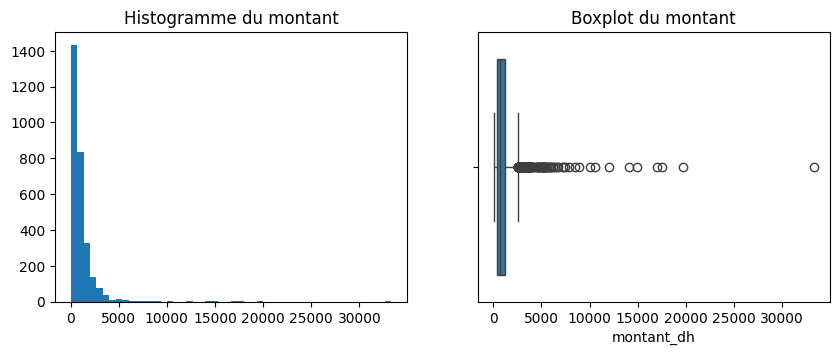

In [8]:
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.hist(df["montant_dh"].dropna(), bins=50)
plt.title("Histogramme du montant")
plt.subplot(1, 2, 2)
sns.boxplot(x=df["montant_dh"])
plt.title("Boxplot du montant")
plt.show()

**Plus grands montants et fraude**

In [9]:
print(df["montant_dh"].nlargest(5))
print("Taux de fraude pour montant > 10000 :", df[df["montant_dh"] > 10000]["fraude"].mean())

2660    33281.23
539     19658.42
1775    17496.64
1557    16962.99
2556    14951.95
Name: montant_dh, dtype: float64
Taux de fraude pour montant > 10000 : 0.0


**Conclusion**

- Non, il ne faut pas forcément supprimer les montants extrêmes : ce sont de vraies opérations possibles (gros virements). Aucune opération de plus de 10 000 DH n'est une fraude. Les supprimer ferait perdre de l'information.

### Question 5 : Proportion de fraudes
On calcule la proportion de chaque classe et on trace le diagramme des deux classes.

**Proportions et diagramme**

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


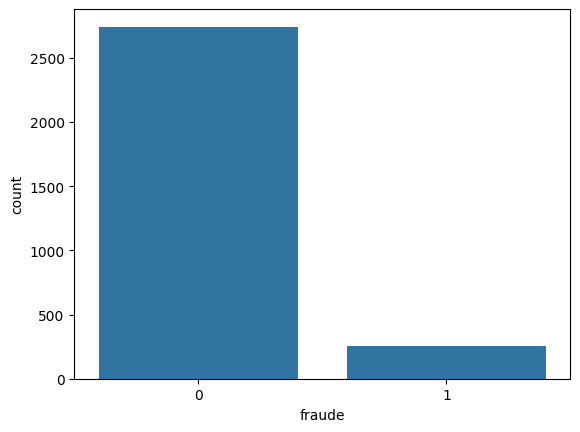

In [10]:
print(df["fraude"].value_counts(normalize=True) * 100)
sns.countplot(x="fraude", data=df)
plt.show()

**Conclusion**

- Il y a 8,6 % de fraudes contre 91,4 % d'opérations normales : le fichier n'est pas équilibré.
- C'est important pour la préparation : on sépare les données avec stratify=y, et on rééquilibre seulement le groupe de référence.

### Question 6 : Identifiants et resultat_enquete
On vérifie que resultat_enquete donne déjà la réponse, en la croisant avec fraude.

**Tableau croisé resultat_enquete et fraude**

In [11]:
print(pd.crosstab(df["resultat_enquete"], df["fraude"]))

fraude               0    1
resultat_enquete           
aucune_fraude     2742    0
fraude_confirmee     0  258


**Conclusion**

- Les identifiants (id_operation, id_client) servent seulement au suivi : ils identifient mais ne décrivent pas l'opération.
- resultat_enquete est connue seulement après l'enquête, donc pas au moment de l'opération. Elle est identique à fraude : c'est une fuite d'information.

## Partie 2 : Préparer les données sans fuite

### Question 7 : Créer X et y
X contient les variables à préparer, y contient la classe fraude. On retire les identifiants et resultat_enquete de X.

**Création de X et y**

In [12]:
y = df["fraude"]
X = df.drop(columns=["id_operation", "id_client", "resultat_enquete", "fraude"])
print(X.columns.tolist())

['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']


### Question 8 : Séparation référence / vérification
On crée 80 % de lignes pour la référence et 20 % pour la vérification, avec la même proportion de fraudes.

**train_test_split avec stratify**

In [13]:
X_ref, X_ver, y_ref, y_ver = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Référence :", X_ref.shape)
print("Vérification :", X_ver.shape)
print("Fraude référence (%) :", round(y_ref.mean() * 100, 2))
print("Fraude vérification (%) :", round(y_ver.mean() * 100, 2))

Référence : (2400, 8)
Vérification : (600, 8)
Fraude référence (%) : 8.58
Fraude vérification (%) : 8.67


**Conclusion**

- Les proportions de fraude sont presque identiques dans les deux groupes (8,58 % et 8,67 %).

### Question 9 : Variables numériques et catégorielles
On sépare les colonnes numériques des colonnes catégorielles.

**Listes de colonnes**

In [14]:
num_cols = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]
cat_cols = ["canal", "appareil", "region", "international"]
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)

Numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Catégorielles : ['canal', 'appareil', 'region', 'international']


**Conclusion**

- canal et region sont des catégories, pas des quantités. Les coder 0, 1, 2, 3 créerait un ordre et des distances qui n'existent pas : on utilise une colonne 0/1 par catégorie (one-hot).

### Question 10 : Pipeline pour les nombres
On remplace les valeurs manquantes par la médiane, puis on applique StandardScaler. Le calcul se fait uniquement sur la référence (fit).

**Pipeline numérique**

In [15]:
pipe_num = Pipeline([
    ("mediane", SimpleImputer(strategy="median")),
    ("echelle", StandardScaler())])
pipe_num.fit(X_ref[num_cols])
print("Médianes :", pipe_num["mediane"].statistics_.round(2))
print("Écarts-types :", pipe_num["echelle"].scale_.round(2))

Médianes : [710.79  87.     3.    11.  ]
Écarts-types : [1327.63   49.49    1.65    7.  ]


### Question 11 : Pipeline pour les catégories
On remplace les valeurs manquantes par la valeur la plus fréquente, puis on applique OneHotEncoder.

**Pipeline catégoriel**

In [16]:
pipe_cat = Pipeline([
    ("frequent", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
pipe_cat.fit(X_ref[cat_cols])
print("Valeurs les plus fréquentes :", pipe_cat["frequent"].statistics_)

Valeurs les plus fréquentes : ['application' 'mobile' 'Draa-Tafilalet' 'non']


### Question 12 : ColumnTransformer
On réunit les deux pipelines. fit_transform sur la référence, transform seulement sur la vérification.

**Transformation des deux groupes**

In [17]:
prep = ColumnTransformer([
    ("num", pipe_num, num_cols),
    ("cat", pipe_cat, cat_cols)])
Xr = prep.fit_transform(X_ref)
Xv = prep.transform(X_ver)
print("Référence :", X_ref.shape, "->", Xr.shape)
print("Vérification :", X_ver.shape, "->", Xv.shape)

Référence : (2400, 8) -> (2400, 18)
Vérification : (600, 8) -> (600, 18)


**Conclusion**

- Le nombre de lignes ne change pas (2400 et 600). Le nombre de colonnes passe de 8 à 18 dans les deux groupes (4 numériques + 14 colonnes one-hot).

### Question 13 : StandardScaler contre RobustScaler
On remplace StandardScaler par RobustScaler, puis on compare la valeur transformée d'un montant ordinaire et d'un montant très élevé.

**ColumnTransformer avec RobustScaler**

In [18]:
pipe_num_rob = Pipeline([
    ("mediane", SimpleImputer(strategy="median")),
    ("echelle", RobustScaler())])
prep_rob = ColumnTransformer([
    ("num", pipe_num_rob, num_cols),
    ("cat", pipe_cat, cat_cols)])
Xr_rob = prep_rob.fit_transform(X_ref)
print("Forme :", Xr_rob.shape)

Forme : (2400, 18)


**Comparaison sur deux montants**

In [19]:
donnees = X_ref[["montant_dh"]].dropna()
standard = StandardScaler().fit(donnees)
robust = RobustScaler().fit(donnees)
exemples = pd.DataFrame({"montant_dh": [700, 33000]}, index=["ordinaire", "très élevé"])
exemples["Standard"] = standard.transform(exemples[["montant_dh"]]).round(2)
exemples["Robust"] = robust.transform(exemples[["montant_dh"]]).round(2)
print(exemples)

            montant_dh  Standard  Robust
ordinaire          700     -0.25   -0.01
très élevé       33000     23.66   37.69


**Conclusion**

- Avec RobustScaler, le montant ordinaire est proche de 0 (centré sur la médiane) et le montant très élevé ressort nettement.
- StandardScaler utilise la moyenne et l'écart-type, qui sont tirés par les extrêmes : l'échelle est déformée.

### Question 14 : Danger de la fuite d'information
On compare la médiane du montant calculée sur la référence seule et sur toutes les lignes.

**Médiane avec et sans la vérification**

In [20]:
print("Médiane (référence seule) :", round(X_ref["montant_dh"].median(), 2))
print("Médiane (toutes les lignes) :", round(X["montant_dh"].median(), 2))

Médiane (référence seule) : 710.79
Médiane (toutes les lignes) : 708.66


**Conclusion**

- Si on calcule les paramètres sur toutes les lignes, le groupe de vérification influence la préparation : il n'est plus vraiment nouveau.
- Les résultats paraissent meilleurs qu'ils ne le sont : c'est une fuite d'information. En pratique, on ne connaît pas les futures transactions.

## Partie 3 : Comparer les méthodes de mise à l'échelle

### Question 15 : Quartiles et IQR
On calcule Q1, Q3 et l'IQR du montant sur la référence.

**Calcul de Q1, Q3 et IQR**

In [21]:
m = X_ref["montant_dh"].dropna()
Q1 = m.quantile(0.25)
Q3 = m.quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", round(Q1, 2))
print("Q3 =", round(Q3, 2))
print("IQR =", round(IQR, 2))

Q1 = 393.1
Q3 = 1249.88
IQR = 856.78


**Conclusion**

- L'IQR mesure la largeur de la zone qui contient la moitié centrale des montants. Il est très peu influencé par les valeurs extrêmes.

### Question 16 : Montants extrêmes (règle 1,5 × IQR)
Les limites sont : bas = Q1 − 1,5 × IQR et haut = Q3 + 1,5 × IQR.

**Détection des extrêmes**

In [22]:
bas = Q1 - 1.5 * IQR
haut = Q3 + 1.5 * IQR
extremes = m[(m < bas) | (m > haut)]
n_ext = len(extremes)
print("Limites :", round(bas, 2), "et", round(haut, 2))
print("Lignes concernées :", n_ext)

Limites : -892.08 et 2535.05
Lignes concernées : 146


**Quelques cas**

In [23]:
cas = df.loc[extremes.index, ["montant_dh", "canal", "fraude"]]
print(cas.sort_values("montant_dh", ascending=False).head(5))

      montant_dh        canal  fraude
2660    33281.23  application       0
539     19658.42  application       0
1775    17496.64     site_web       0
2556    14951.95  application       0
65      14135.85  application       0


**Conclusion**

- 146 lignes sont concernées. Elles ne sont pas nécessairement des erreurs : ce sont souvent de vrais gros montants (les plus grands ne sont pas des fraudes).

### Question 17 : Conserver ou limiter les extrêmes
On compare deux choix : garder les montants, ou les limiter aux seuils calculés sur la référence.

**Deux boxplots**

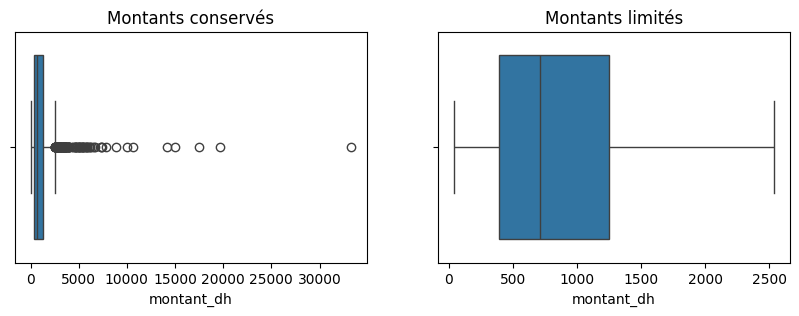

In [24]:
m_limite = m.clip(lower=bas, upper=haut)
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
sns.boxplot(x=m)
plt.title("Montants conservés")
plt.subplot(1, 2, 2)
sns.boxplot(x=m_limite)
plt.title("Montants limités")
plt.show()

**Conclusion**

- Il faut justifier ce choix : limiter les montants modifie les données et peut effacer un signal utile. Ici on conserve les extrêmes, car ce sont de vraies opérations.

### Question 18 : MinMaxScaler, StandardScaler et RobustScaler
On ajuste chaque méthode sur la référence (fit), puis on transforme la vérification (transform).

**Ajustement sur la référence, transformation de la vérification**

In [25]:
donnees_ref = X_ref[["montant_dh"]].dropna()
donnees_ver = X_ver[["montant_dh"]].dropna()
minmax = MinMaxScaler().fit(donnees_ref)
zscore = StandardScaler().fit(donnees_ref)
robust = RobustScaler().fit(donnees_ref)
print("MinMax  : min =", minmax.transform(donnees_ver).min().round(3), " max =", minmax.transform(donnees_ver).max().round(3))
print("Z-score : min =", zscore.transform(donnees_ver).min().round(3), " max =", zscore.transform(donnees_ver).max().round(3))
print("Robust  : min =", robust.transform(donnees_ver).min().round(3), " max =", robust.transform(donnees_ver).max().round(3))

MinMax  : min = 0.001  max = 0.509
Z-score : min = -0.718  max = 11.789
Robust  : min = -0.757  max = 18.969


### Question 19 : Comparaison sur quatre montants
On choisit trois montants habituels et un montant très élevé.

**Tableau avant / après**

In [26]:
tableau = pd.DataFrame({"montant_dh": [400, 700, 1200, 33000]},
                       index=["habituel 1", "habituel 2", "habituel 3", "très élevé"])
tableau["MinMax"] = minmax.transform(tableau[["montant_dh"]]).round(3)
tableau["Z-score"] = zscore.transform(tableau[["montant_dh"]]).round(3)
tableau["Robust"] = robust.transform(tableau[["montant_dh"]]).round(3)
print(tableau)

            montant_dh  MinMax  Z-score  Robust
habituel 1         400   0.011   -0.468  -0.363
habituel 2         700   0.020   -0.246  -0.013
habituel 3        1200   0.035    0.124   0.571
très élevé       33000   0.992   23.658  37.687


**Conclusion**

- Min-Max est la méthode la plus perturbée : le montant très élevé fixe l'échelle, donc les trois montants habituels sont écrasés entre 0,01 et 0,04.

### Question 20 : Histogrammes du montant transformé
On trace les trois histogrammes sur la référence.

**Trois histogrammes**

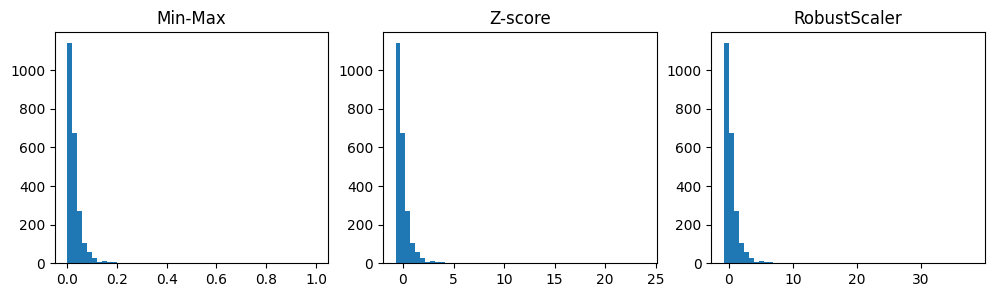

In [27]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 3, 1)
plt.hist(minmax.transform(donnees_ref), bins=50)
plt.title("Min-Max")
plt.subplot(1, 3, 2)
plt.hist(zscore.transform(donnees_ref), bins=50)
plt.title("Z-score")
plt.subplot(1, 3, 3)
plt.hist(robust.transform(donnees_ref), bins=50)
plt.title("RobustScaler")
plt.show()

**Conclusion**

- La forme ne change pas, seule l'échelle change.
- Min-Max utilise le min et le max ; Z-score utilise la moyenne et l'écart-type ; RobustScaler utilise la médiane et l'IQR (peu sensible aux extrêmes).

### Question 21 : Min-Max peut-il dépasser 1 ?
On vérifie avec un petit exemple, puis sur nos données.

**Petit exemple numérique**

In [28]:
petit = pd.DataFrame({"montant_dh": [0, 100]})
mm = MinMaxScaler().fit(petit)          # min = 0, max = 100
nouveau = pd.DataFrame({"montant_dh": [150]})
print("150 devient :", mm.transform(nouveau)[0][0])

150 devient : 1.5


**Sur nos données**

In [29]:
grand = pd.DataFrame({"montant_dh": [50000]})
print("50000 devient :", minmax.transform(grand)[0][0].round(2))

50000 devient : 1.5


**Conclusion**

- Oui : Min-Max a appris le min et le max de la référence. Une valeur plus grande que ce maximum donne un résultat supérieur à 1.

## Partie 4 : Préparer des classes déséquilibrées

### Question 22 : Comptage des classes
On compte les lignes de chaque classe dans la référence et on calcule le rapport.

**Effectifs et rapport**

In [30]:
print(y_ref.value_counts())
print("Rapport :", round((y_ref == 0).sum() / (y_ref == 1).sum(), 2))

fraude
0    2194
1     206
Name: count, dtype: int64
Rapport : 10.65


### Question 23 : Suréchantillonnage (RandomOverSampler)
On applique RandomOverSampler uniquement à la référence transformée (Xr).

**Avant et après**

In [31]:
ros = RandomOverSampler(random_state=42)
Xr_sur, y_sur = ros.fit_resample(Xr, y_ref)
print("Avant :", y_ref.value_counts().to_dict())
print("Après :", y_sur.value_counts().to_dict())

Avant : {0: 2194, 1: 206}
Après : {0: 2194, 1: 2194}


**Les nouvelles lignes sont-elles des copies ?**

In [32]:
print("Lignes en double avant :", pd.DataFrame(Xr).duplicated().sum())
print("Lignes en double après :", pd.DataFrame(Xr_sur).duplicated().sum())

Lignes en double avant : 0
Lignes en double après : 1988


**Conclusion**

- Oui : les nouvelles lignes sont des copies de lignes existantes (1988 lignes en double ajoutées).

### Question 24 : Sous-échantillonnage (RandomUnderSampler)
On repart de la référence initiale et on supprime des opérations normales.

**Lignes conservées et supprimées**

In [33]:
rus = RandomUnderSampler(random_state=42)
Xr_sous, y_sous = rus.fit_resample(Xr, y_ref)
print("Après :", y_sous.value_counts().to_dict())
print("Lignes conservées :", len(y_sous))
print("Lignes supprimées :", len(y_ref) - len(y_sous))

Après : {0: 206, 1: 206}
Lignes conservées : 412
Lignes supprimées : 1988


**Conclusion**

- Le risque est de perdre beaucoup d'information utile de la classe majoritaire.

### Question 25 : SMOTE sur un petit exemple
On crée un petit tableau à deux variables : 6 opérations normales et 3 fraudes.

**Valeurs réelles et valeurs synthétiques**

In [34]:
petit = pd.DataFrame({"montant": [100, 120, 110, 130, 105, 115, 2000, 2400, 2200],
                      "nb_ops":  [1, 2, 1, 2, 1, 2, 8, 9, 10]})
cible = pd.Series([0, 0, 0, 0, 0, 0, 1, 1, 1])
Xs, ys = SMOTE(k_neighbors=2, random_state=42).fit_resample(petit, cible)
print("Fraudes réelles :")
print(petit[cible == 1])
print("Fraudes synthétiques :")
print(Xs.iloc[len(petit):].round(1))

Fraudes réelles :
   montant  nb_ops
6     2000       8
7     2400       9
8     2200      10
Fraudes synthétiques :
    montant  nb_ops
9      2088       8
10     2319       9
11     2310       9


**Conclusion**

- SMOTE choisit une fraude réelle et l'un de ses voisins, puis crée un point nouveau entre les deux : ce n'est pas une copie.

### Question 26 : SMOTE et one-hot
Question de cours, sans code.

**Conclusion**

- SMOTE calcule des valeurs intermédiaires : dans une colonne one-hot (0 ou 1), il peut créer des valeurs comme 0,37 qui n'ont pas de sens.
- La méthode conçue pour les données qui mêlent nombres et catégories est SMOTENC.

### Question 27 : Tableau des effectifs
On présente les effectifs avant et après rééquilibrage.

**Tableau récapitulatif**

In [35]:
tableau = pd.DataFrame({
    "fraude = 0": [(y_ref == 0).sum(), (y_sur == 0).sum(), (y_sous == 0).sum(), (y_ver == 0).sum()],
    "fraude = 1": [(y_ref == 1).sum(), (y_sur == 1).sum(), (y_sous == 1).sum(), (y_ver == 1).sum()]},
    index=["Avant", "Sur-échantillonnage", "Sous-échantillonnage", "Vérification"])
print(tableau)

                      fraude = 0  fraude = 1
Avant                       2194         206
Sur-échantillonnage         2194        2194
Sous-échantillonnage         206         206
Vérification                 548          52


**Conclusion**

- Le groupe de vérification ne doit pas changer : il doit rester comme la réalité (peu de fraudes) pour que la vérification soit honnête.

## Partie 5 : Vérifier et enregistrer les données préparées

### Question 28 : Transformateur final
Médiane et RobustScaler pour les nombres, valeur fréquente et OneHotEncoder pour les catégories.

**Création du transformateur**

In [36]:
final = ColumnTransformer([
    ("num", Pipeline([("mediane", SimpleImputer(strategy="median")),
                      ("echelle", RobustScaler())]), num_cols),
    ("cat", Pipeline([("frequent", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
print("Transformateur créé")

Transformateur créé


### Question 29 : Ajustement et vérifications
On calcule les paramètres sur la référence uniquement, puis on applique le même transformateur aux deux groupes.

**fit sur la référence, transform sur les deux groupes**

In [37]:
final.fit(X_ref)
F_ref = final.transform(X_ref)
F_ver = final.transform(X_ver)
print("Tailles :", F_ref.shape, F_ver.shape)
print("Valeurs manquantes :", np.isnan(F_ref).sum(), "et", np.isnan(F_ver).sum())

Tailles : (2400, 18) (600, 18)
Valeurs manquantes : 0 et 0


**Conclusion**

- Les deux groupes ont 18 colonnes et aucune valeur manquante.

### Question 30 : Catégorie inconnue
On remplace le canal d'une ligne par une valeur que la référence n'a jamais vue.

**Transformation d'une ligne avec un canal inconnu**

In [38]:
ligne = X_ref.iloc[[0]].copy()
ligne["canal"] = "distributeur_automatique"
resultat = final.transform(ligne)
print(final.get_feature_names_out()[4:8])
print(resultat[0][4:8])

['cat__canal_agence' 'cat__canal_application' 'cat__canal_site_web'
 'cat__canal_telephone']
[0. 0. 0. 0.]


**Conclusion**

- La transformation fonctionne : toutes les colonnes canal valent 0 pour cette ligne.
- handle_unknown="ignore" évite une erreur quand une catégorie inconnue apparaît. Sans cette option, OneHotEncoder s'arrêterait avec une erreur.

### Question 31 : Enregistrer avec joblib
On enregistre le transformateur, on le recharge et on compare les résultats sur 5 lignes.

**Sauvegarde, rechargement et vérification**

In [39]:
joblib.dump(final, "preprocesseur_final.joblib")
recharge = joblib.load("preprocesseur_final.joblib")
echantillon = X_ver.head(5)
print("Mêmes valeurs :", np.allclose(final.transform(echantillon), recharge.transform(echantillon)))

Mêmes valeurs : True


**Conclusion**

- Le transformateur rechargé donne les mêmes valeurs : il a gardé les médianes et les échelles apprises.

### Question 32 : Bilan
On résume le travail avec les chiffres obtenus.

**Résumé**

In [40]:
print("Doublons retirés :", n_doublons)
print("Valeurs manquantes traitées :", X.isnull().sum().sum())
print("Valeurs extrêmes observées :", n_ext)
print("Sur-échantillonnage :", len(y_sur), "lignes")
print("Sous-échantillonnage :", len(y_sous), "lignes")

Doublons retirés : 45
Valeurs manquantes traitées : 673
Valeurs extrêmes observées : 146
Sur-échantillonnage : 4388 lignes
Sous-échantillonnage : 412 lignes
